# Parte 1.- Recordatorio de homografías

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import HBox, VBox, Layout

# ==========================================
# 1. GENERAR EL MISMO TABLERO DE LA SESIÓN 1
# ==========================================
size_grid = int(400)
grid_size = int(50)
chessboard = np.zeros((size_grid, size_grid, 3), dtype=np.uint8)

for i in range(size_grid):
    for j in range(size_grid):
        if (i // grid_size + j // grid_size) % 2 == 0:
            chessboard[i, j] = [255, 255, 255]  # Blanco/Claro
        else:
            chessboard[i, j] =  [40, 40, 40]     # Gris oscuro

# ==========================================
# 2. DEFINICIÓN DE CONTROLES DESLIZANTES (SLIDERS)
# ==========================================
style = {'description_width': 'initial'}
layout_slider = Layout(width='280px')

# Bloque Afín (Azul)
h11 = widgets.FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description='h11 (Escala X)', style=style, layout=layout_slider)
h12 = widgets.FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, description='h12 (Cizalladura X)', style=style, layout=layout_slider)
h21 = widgets.FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, description='h21 (Cizalladura Y)', style=style, layout=layout_slider)
h22 = widgets.FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description='h22 (Escala Y)', style=style, layout=layout_slider)

# Bloque de Traslación (Verde)
h13 = widgets.FloatSlider(value=0.0, min=-200.0, max=200.0, step=10.0, description='h13 (Traslación X)', style=style, layout=layout_slider)
h23 = widgets.FloatSlider(value=0.0, min=-200.0, max=200.0, step=10.0, description='h23 (Traslación Y)', style=style, layout=layout_slider)

# Bloque Proyectivo (Rojo)
h31 = widgets.FloatSlider(value=0.0, min=-0.003, max=0.003, step=0.0002, readout_format='.4f', description='h31 (Fuga Horizontal)', style=style, layout=layout_slider)
h32 = widgets.FloatSlider(value=0.0, min=-0.003, max=0.003, step=0.0002, readout_format='.4f', description='h32 (Fuga Vertical)', style=style, layout=layout_slider)

# ==========================================
# 3. BOTÓN DE RESET
# ==========================================
btn_reset = widgets.Button(
    description='Resetear Matriz (Identidad)',
    button_style='warning', # Color naranja/amarillo de atención
    icon='refresh',
    layout=Layout(width='280px', margin='15px 0px 0px 0px')
)

def reset_values(b):
    h11.value = 1.0
    h12.value = 0.0
    h13.value = 0.0
    h21.value = 0.0
    h22.value = 1.0
    h23.value = 0.0
    h31.value = 0.0
    h32.value = 0.0

btn_reset.on_click(reset_values)

# ==========================================
# 4. FUNCIÓN AUXILIAR PARA DIBUJAR LA MATRIZ DE COLORES
# ==========================================
def dibujar_matriz_colores(ax, H):
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(2.5, -0.5) # Invertir eje Y para mantener indexación habitual de matrices
    ax.set_aspect('equal')
    
    # Azul pastel para afín, Verde pastel para traslación, Rojo pastel para perspectiva, Gris para escala global
    colors = [
        ['#D6EAF8', '#D6EAF8', '#D4EFDF'],
        ['#D6EAF8', '#D6EAF8', '#D4EFDF'],
        ['#FADBD8', '#FADBD8', '#EAECEE']
    ]
    
    labels = [
        ['h11 (Esc X)', 'h12 (Ciz X)', 'h13 (Tras X)'],
        ['h21 (Ciz Y)', 'h22 (Esc Y)', 'h23 (Tras Y)'],
        ['h31 (Fug H)', 'h32 (Fug V)', 'h33 (Fijo)']
    ]
    
    for r in range(3):
        for c in range(3):
            # Dibujar celda de color
            rect = plt.Rectangle((c-0.5, r-0.5), 1.0, 1.0, facecolor=colors[r][c], edgecolor='white', linewidth=3)
            ax.add_patch(rect)
            
            # Valor numérico actual
            val_str = f"{H[r,c]:.4f}" if (r == 2 and c < 2) else f"{H[r,c]:.2f}"
            ax.text(c, r-0.12, val_str, ha='center', va='center', fontsize=12, fontweight='bold', color='#2C3E50')
            
            # Etiqueta de la propiedad geométrica
            ax.text(c, r+0.22, labels[r][c], ha='center', va='center', fontsize=8, color='#5D6D7E', fontweight='semibold')
            
    ax.axis('off')
    ax.set_title("Estructura de la Matriz H", fontsize=13, fontweight='bold', pad=15)

# ==========================================
# 5. RENDERIZADO PRINCIPAL
# ==========================================
def actualizar_simulacion(h11_v, h12_v, h13_v, h21_v, h22_v, h23_v, h31_v, h32_v):
    # Crear matriz H
    H = np.array([
        [float(h11_v), float(h12_v), float(h13_v)],
        [float(h21_v), float(h22_v), float(h23_v)],
        [float(h31_v), float(h32_v), 1.0]
    ], dtype=np.float64)
    
    # Aplicar deformación con OpenCV
    img_warped = cv2.warpPerspective(chessboard, H, (int(size_grid), int(size_grid)))
    
    # Lienzo de 3 paneles (Matriz coloreada | Tablero Original | Tablero Deformado)
    fig, axes = plt.subplots(int(1), int(3), figsize=(int(15), int(5.5)))
    
    # Panel 1: Matriz Coloreada
    dibujar_matriz_colores(axes[0], H)
    
    # Panel 2: Tablero Original
    axes[1].imshow(chessboard)
    axes[1].set_title("Tablero Original (Mundo)", fontsize=11, fontweight='bold')
    axes[1].axis('off')
    
    # Panel 3: Tablero Deformado
    axes[2].imshow(img_warped)
    axes[2].set_title("Tablero Proyectado (Cámara)", fontsize=11, fontweight='bold')
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Vincular actualización interactiva de los controles a la función principal
out = widgets.interactive_output(
    actualizar_simulacion,
    {
        'h11_v': h11, 'h12_v': h12, 'h13_v': h13,
        'h21_v': h21, 'h22_v': h22, 'h23_v': h23,
        'h31_v': h31, 'h32_v': h32
    }
)

# ==========================================
# 6. DISTRIBUCIÓN VISUAL DE LA INTERFAZ
# ==========================================
caja_afin = VBox([widgets.HTML("<b>Bloque Afín (Azul)</b>"), h11, h12, h21, h22], layout=Layout(border='2px solid #D6EAF8', padding='10px', margin='5px'))
caja_tras = VBox([widgets.HTML("<b>Traslación (Verde)</b>"), h13, h23], layout=Layout(border='2px solid #D4EFDF', padding='10px', margin='5px'))
caja_proj = VBox([widgets.HTML("<b>Fila Proyectiva (Rojo)</b>"), h31, h32, btn_reset], layout=Layout(border='2px solid #FADBD8', padding='10px', margin='5px'))

controles = HBox([caja_afin, caja_tras, caja_proj])
interface = VBox([controles, out])

display(interface)

## Un segundo ejemplo: morphing

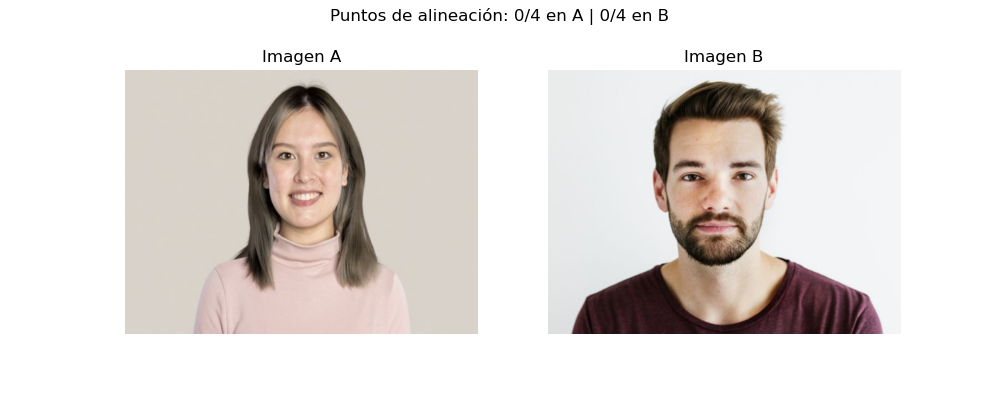

Output()

In [2]:
%matplotlib widget

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

puntos_A = []
puntos_B = []

# Cargar imágenes originales (OpenCV las lee en formato BGR nativo)
imgA_bgr = cv2.imread('foto1.jpg')
imgB_bgr = cv2.imread('foto2.jpg')

# Redimensionar
h, w = 600, 800
imgA_bgr = cv2.resize(imgA_bgr, (w, h))
imgB_bgr = cv2.resize(imgB_bgr, (w, h))

# Contenedor para el resultado final
contenedor_morphing = widgets.Output()

# Convertir a RGB SOLO para que Matplotlib las pinte con los colores reales
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle("Puntos de alineación: 0/4 en A | 0/4 en B")

ax1.imshow(cv2.cvtColor(imgA_bgr, cv2.COLOR_BGR2RGB))
ax1.set_title("Imagen A")
ax1.axis('off')

ax2.imshow(cv2.cvtColor(imgB_bgr, cv2.COLOR_BGR2RGB))
ax2.set_title("Imagen B")
ax2.axis('off')

def onclick(event):
    if event.inaxes is None: return
    
    if event.inaxes == ax1 and len(puntos_A) < 4:
        puntos_A.append([event.xdata, event.ydata])
        ax1.plot(event.xdata, event.ydata, 'ro', markersize=8)
        
    elif event.inaxes == ax2 and len(puntos_B) < 4:
        puntos_B.append([event.xdata, event.ydata])
        ax2.plot(event.xdata, event.ydata, 'ro', markersize=8)
        
    fig.suptitle(f"Puntos de alineación: {len(puntos_A)}/4 en A | {len(puntos_B)}/4 en B")
    fig.canvas.draw()
        
    if len(puntos_A) == 4 and len(puntos_B) == 4:
        fig.canvas.mpl_disconnect(cid)
        fig.suptitle("¡Puntos capturados! Desplázate hacia abajo.")
        fig.canvas.draw()
        
        pt_A = np.float32(puntos_A)
        pt_B = np.float32(puntos_B)

        # Cálculo de centroides y escala
        A_avg = np.mean(pt_A, axis=0)
        B_avg = np.mean(pt_B, axis=0)

        A_dists = np.linalg.norm(pt_A - A_avg, axis=1)
        B_dists = np.linalg.norm(pt_B - B_avg, axis=1)
        scale = np.mean(A_dists) / np.mean(B_dists)

        translation = A_avg - B_avg * scale

        M_align = np.float32([[scale, 0, translation[0]], 
                              [0, scale, translation[1]]])

        # Alineamos la imagen en BGR directamente
        imgB_aligned_bgr = cv2.warpAffine(imgB_bgr, M_align, (w, h), flags=cv2.INTER_LINEAR)

        with contenedor_morphing:
            iniciar_interfaz_morphing(imgA_bgr, imgB_aligned_bgr)

cid = fig.canvas.mpl_connect('button_press_event', onclick)
plt.show()

def iniciar_interfaz_morphing(imgA, imgB_aligned):
    # Al pasarle imágenes BGR a cv2.imencode, el JPG resultante tendrá los colores 100% reales
    _, encoded_img = cv2.imencode('.jpg', imgA)
    visor_imagen = widgets.Image(value=encoded_img.tobytes(), format='jpg', width=w, height=h)
    
    def actualizar_morphing(cambio):
        t = cambio['new']
        # Mezcla píxel a píxel en espacio BGR
        img_mezcla = cv2.addWeighted(imgA, 1.0 - t, imgB_aligned, t, 0)
        
        _, encoded_img = cv2.imencode('.jpg', img_mezcla)
        visor_imagen.value = encoded_img.tobytes()

    slider = widgets.FloatSlider(
        value=0.0,
        min=0.0,
        max=1.0,
        step=0.02,
        description='Transición t:',
        layout=widgets.Layout(width='80%')
    )
    
    slider.observe(actualizar_morphing, names='value')
    display(slider, visor_imagen)

display(contenedor_morphing)

# Segunda parte.- SVD

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import HBox, VBox, Layout

# ==========================================
# 1. GENERACIÓN DE GEOMETRÍA ORIGINAL
# ==========================================
# Creamos un círculo unitario denso
num_puntos = int(300)
theta = np.linspace(0, 2 * np.pi, num_puntos)
circulo_x = np.cos(theta)
circulo_y = np.sin(theta)
puntos_circulo = np.vstack((circulo_x, circulo_y)) # Matriz de 2 x 300

# Colores del espectro HSV para ver rotaciones de los puntos individuales
colores = theta

# Vectores de la base canónica (Ejes X e Y originales para ver la orientación)
flecha_x = np.array([[0.0, 1.0], [0.0, 0.0]], dtype=np.float64) # Vector (1, 0)
flecha_y = np.array([[0.0, 0.0], [0.0, 1.0]], dtype=np.float64) # Vector (0, 1)

# ==========================================
# 2. FUNCIÓN DE RENDERIZADO EN 4 PASOS
# ==========================================
def visualizar_svd_pasos(a11, a12, a21, a22):
    # Matriz de transformación lineal A
    A = np.array([
        [float(a11), float(a12)],
        [float(a21), float(a22)]
    ], dtype=np.float64)
    
    # Calcular la SVD: A = U * S_diag * Vt
    try:
        U, S, Vt = np.linalg.svd(A)
    except np.linalg.linalg.LinAlgError:
        # En caso de matrices singulares extremas
        return
        
    S_mat = np.diag(S)
    
    # --- CÁLCULO DE LOS PASOS ---
    # Paso 0: Estado original (Círculo Unitario)
    p_paso0 = puntos_circulo
    fx_0, fy_0 = flecha_x, flecha_y
    
    # Paso 1: Aplicación de Vt (Rotación Inicial)
    p_paso1 = Vt @ puntos_circulo
    fx_1 = Vt @ flecha_x
    fy_1 = Vt @ flecha_y
    
    # Paso 2: Aplicación de Sigma * Vt (Estiramiento de ejes)
    p_paso2 = S_mat @ Vt @ puntos_circulo
    fx_2 = S_mat @ Vt @ flecha_x
    fy_2 = S_mat @ Vt @ flecha_y
    
    # Paso 3: Aplicación de U * Sigma * Vt (Rotación Final)
    p_paso3 = U @ S_mat @ Vt @ puntos_circulo # Equivalente a A @ puntos_circulo
    fx_3 = A @ flecha_x
    fy_3 = A @ flecha_y
    
    # --- CONFIGURACIÓN DEL LIENZO ---
    # Creamos 4 subplots alineados
    fig, axes = plt.subplots(int(1), int(4), figsize=(int(18), int(4.8)))
    titulos = [
        "Paso 0: Círculo Unitario\n(Original)",
        "Paso 1: Rotación ($V^T$)\n(Giro del espacio)",
        "Paso 2: Estiramiento ($\Sigma$)\n(Valores singulares)",
        "Paso 3: Rotación ($U$)\n(Transformación Final)"
    ]
    
    datos_pasos = [
        (p_paso0, fx_0, fy_0),
        (p_paso1, fx_1, fy_1),
        (p_paso2, fx_2, fy_2),
        (p_paso3, fx_3, fy_3)
    ]
    
    # Determinamos límites simétricos dinámicos para que no se corte el gráfico
    max_val = max(np.max(np.abs(p_paso3)), 1.5)
    lim = float(max_val * 1.1)
    
    for idx, (pts, fx, fy) in enumerate(datos_pasos):
        ax = axes[idx]
        ax.set_aspect('equal')
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.axhline(0, color='black', linewidth=0.8, alpha=0.3)
        ax.axvline(0, color='black', linewidth=0.8, alpha=0.3)
        
        # Pintar el círculo/elipse con el mapa de colores HSV para rastrear los puntos
        ax.scatter(pts[0], pts[1], c=colores, cmap='hsv', s=10, zorder=2)
        
        # Dibujar los vectores de la base canónica transformada (Eje X en Rojo, Eje Y en Azul)
        ax.quiver(0, 0, fx[0, 1], fx[1, 1], angles='xy', scale_units='xy', scale=1, color='#E74C3C', width=0.015, zorder=3, label='Eje X')
        ax.quiver(0, 0, fy[0, 1], fy[1, 1], angles='xy', scale_units='xy', scale=1, color='#3498DB', width=0.015, zorder=3, label='Eje Y')
        
        ax.set_title(titulos[idx], fontsize=11, fontweight='bold', pad=10)
        if idx == 0:
            ax.legend(loc='lower left', fontsize=8)
            
    plt.tight_layout()
    plt.show()
    
    # Imprimir valores de la factorización en consola para asociarlos con los gráficos
    print("=" * 90)
    print(" ANÁLISIS MATRICIAL SVD DE LA TRANSFORMACIÓN ACTUAL")
    print("=" * 90)
    print(f"Matriz de Entrada A:\n{A}\n")
    print(f"1. Rotación Vt (Paso 1):\n{Vt}\n")
    print(f"2. Valores Singulares diagonalizados Sigma (Paso 2):\n{S_mat}")
    print(f"   (Semieje Mayor (Sigma 1): {S[0]:.4f} | Semieje Menor (Sigma 2): {S[1]:.4f})\n")
    print(f"3. Rotación Final U (Paso 3):\n{U}")
    print("=" * 90)

# ==========================================
# 3. INTERFAZ DE USUARIO E IPYWIDGETS
# ==========================================
style = {'description_width': 'initial'}
layout_slider = Layout(width='220px')

# Controles de la matriz A
a11_s = widgets.FloatSlider(value=1.5, min=-3.0, max=3.0, step=0.1, description='a11', style=style, layout=layout_slider)
a12_s = widgets.FloatSlider(value=0.5, min=-3.0, max=3.0, step=0.1, description='a12', style=style, layout=layout_slider)
a21_s = widgets.FloatSlider(value=0.2, min=-3.0, max=3.0, step=0.1, description='a21', style=style, layout=layout_slider)
a22_s = widgets.FloatSlider(value=0.8, min=-3.0, max=3.0, step=0.1, description='a22', style=style, layout=layout_slider)

# Botones con Presets interesantes para el aula
btn_shear = widgets.Button(description='Preset: Cizalladura', button_style='info', layout=Layout(width='160px'))
btn_rot = widgets.Button(description='Preset: Rotación Pura', button_style='info', layout=Layout(width='160px'))
btn_sing = widgets.Button(description='Preset: Matriz Singular (Rango 1)', button_style='danger', layout=Layout(width='220px'))

def set_preset_shear(b):
    a11_s.value, a12_s.value = 1.0, 1.5
    a21_s.value, a22_s.value = 0.0, 1.0

def set_preset_rot(b):
    angle = np.radians(45) # Rotación de 45 grados
    a11_s.value, a12_s.value = np.cos(angle), -np.sin(angle)
    a21_s.value, a22_s.value = np.sin(angle), np.cos(angle)

def set_preset_singular(b):
    # Las filas son linealmente dependientes (el círculo colapsará a una línea)
    a11_s.value, a12_s.value = 1.0, 2.0
    a21_s.value, a22_s.value = 0.5, 1.0

btn_shear.on_click(set_preset_shear)
btn_rot.on_click(set_preset_rot)
btn_sing.on_click(set_preset_singular)

# Organizar visualmente los controles
out_svd = widgets.interactive_output(
    visualizar_svd_pasos,
    {'a11': a11_s, 'a12': a12_s, 'a21': a21_s, 'a22': a22_s}
)

fila_controles = HBox([a11_s, a12_s, a21_s, a22_s])
fila_botones = HBox([widgets.HTML("<b>Presets de Clase: </b>"), btn_shear, btn_rot, btn_sing], layout=Layout(align_items='center', margin='10px 0px'))

interface_svd = VBox([
    widgets.HTML("<h3>Explorador Dinámico de la SVD (A = U * Σ * Vᵀ)</h3>"),
    fila_controles,
    fila_botones,
    out_svd
])

display(interface_svd)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import HBox, VBox, Layout

# ==========================================
# 1. GEOMETRÍA ORIGINAL DE REFERENCIA
# ==========================================
num_puntos = int(300)
theta_puntos = np.linspace(0, 2 * np.pi, num_puntos)
circulo_x = np.cos(theta_puntos)
circulo_y = np.sin(theta_puntos)
puntos_circulo = np.vstack((circulo_x, circulo_y)) # 2 x 300

# Colores del espectro HSV para seguir el rastro de cada punto
colores = theta_puntos

# Representamos los vectores de la base canónica como puntos columna (2x1)
v_x = np.array([[1.0], [0.0]], dtype=np.float64) # Eje X
v_y = np.array([[0.0], [1.0]], dtype=np.float64) # Eje Y

# ==========================================
# 2. FUNCIÓN AUXILIAR: ROTACIÓN PURA RIGIDA SO(2)
# ==========================================
def interpolar_rotacion_pura(R, fraction):
    """
    Interpola de forma rígida desde la Identidad hasta la matriz R (que ya se garantiza con det = 1).
    """
    # Extraemos el ángulo de la matriz ortogonal
    theta = np.arctan2(R[1, 0], R[0, 0])
    theta_t = fraction * theta
    
    # Reconstruimos la matriz de rotación pura sin deformación
    return np.array([
        [np.cos(theta_t), -np.sin(theta_t)],
        [np.sin(theta_t),  np.cos(theta_t)]
    ], dtype=np.float64)

# ==========================================
# 3. FUNCIÓN DE ANIMACIÓN TEMPORAL PERFECCIONADA
# ==========================================
def animar_svd(a11, a12, a21, a22, t):
    A = np.array([
        [float(a11), float(a12)],
        [float(a21), float(a22)]
    ], dtype=np.float64)
    
    t = float(t)
    
    try:
        U, S, Vt = np.linalg.svd(A)
    except np.linalg.linalg.LinAlgError:
        return
        
    # --- ALGORITMO DE CORRECCIÓN SO(2) ---
    d_U = np.linalg.det(U)
    d_V = np.linalg.det(Vt)
    
    # Forzamos det(U) = 1 multiplicando la segunda columna por su determinante
    U_SO3 = U.copy()
    U_SO3[:, 1] *= d_U
    
    # Forzamos det(Vt) = 1 multiplicando la segunda fila por su determinante
    Vt_SO3 = Vt.copy()
    Vt_SO3[1, :] *= d_V
    
    # El signo de la inversión (si existe) se absorbe en el segundo valor singular
    s1 = S[0]
    s2 = d_U * d_V * S[1]
    
    I = np.eye(2, dtype=np.float64)
    
    # --- MOTOR DE INTERPOLACIÓN CONTINUA ---
    if t <= 1.0/3.0:
        # FASE 1: De Identidad I a Vt (Primer Giro Rígido sin reflexiones)
        alpha = 3.0 * t
        M_t = interpolar_rotacion_pura(Vt_SO3, alpha)
        fase_nombre = "Fase 1: Giro Inicial ($V^T$)"
        formula_str = r"$M(t) = R_{V^T}(\alpha)$"
        progreso = alpha * 100.0
        color_fase = "#3498DB" # Azul
        
    elif t <= 2.0/3.0:
        # FASE 2: De Vt a Sigma * Vt (Estiramiento y posible reflexión controlada)
        beta = 3.0 * (t - 1.0/3.0)
        # Interpolamos los valores de escala de forma independiente
        s1_t = 1.0 + beta * (s1 - 1.0)
        s2_t = 1.0 + beta * (s2 - 1.0)
        
        Sigma_t = np.diag([s1_t, s2_t])
        M_t = Sigma_t @ Vt_SO3
        fase_nombre = "Fase 2: Estiramiento ($\Sigma$)"
        formula_str = r"$M(t) = \Sigma(\beta) V^T$"
        progreso = beta * 100.0
        color_fase = "#2ECC71" # Verde
        
    else:
        # FASE 3: De Sigma * Vt a U * Sigma * Vt (Giro Final Rígido sin reflexiones)
        gamma = 3.0 * (t - 2.0/3.0)
        U_t = interpolar_rotacion_pura(U_SO3, gamma)
        # Reconstruimos la matriz diagonal final para la fase 3
        Sigma_final = np.diag([s1, s2])
        M_t = U_t @ Sigma_final @ Vt_SO3
        fase_nombre = "Fase 3: Giro Final ($U$)"
        formula_str = r"$M(t) = R_U(\gamma) \Sigma V^T$"
        progreso = gamma * 100.0
        color_fase = "#E74C3C" # Rojo

    # Aplicamos la transformación a la geometría
    puntos_transformados = M_t @ puntos_circulo
    
    # Transformamos las flechas de los ejes canónicos
    vx_t = M_t @ v_x
    vy_t = M_t @ v_y
    
    # --- RENDERIZADO GRÁFICO ---
    fig, axes = plt.subplots(int(1), int(2), figsize=(int(12), int(5.5)))
    
    max_val = max(np.max(np.abs(A @ puntos_circulo)), 1.5)
    lim = float(max_val * 1.15)
    
    # Panel 1: Estado Original (Estático)
    axes[0].set_aspect('equal')
    axes[0].set_xlim(-lim, lim)
    axes[0].set_ylim(-lim, lim)
    axes[0].grid(True, linestyle='--', alpha=0.4)
    axes[0].scatter(puntos_circulo[0], puntos_circulo[1], c=colores, cmap='hsv', s=8)
    axes[0].quiver(0.0, 0.0, float(v_x[0,0]), float(v_x[1,0]), angles='xy', scale_units='xy', scale=1, color='#C0392B', width=0.012)
    axes[0].quiver(0.0, 0.0, float(v_y[0,0]), float(v_y[1,0]), angles='xy', scale_units='xy', scale=1, color='#2980B9', width=0.012)
    axes[0].set_title("Espacio Original (Paso 0)", fontsize=11, fontweight='bold')
    
    # Panel 2: Transformación Animada (Dinámico)
    axes[1].set_aspect('equal')
    axes[1].set_xlim(-lim, lim)
    axes[1].set_ylim(-lim, lim)
    axes[1].grid(True, linestyle='--', alpha=0.4)
    axes[1].scatter(puntos_transformados[0], puntos_transformados[1], c=colores, cmap='hsv', s=12, zorder=2)
    axes[1].quiver(0.0, 0.0, float(vx_t[0,0]), float(vx_t[1,0]), angles='xy', scale_units='xy', scale=1, color='#E74C3C', width=0.015, zorder=3)
    axes[1].quiver(0.0, 0.0, float(vy_t[0,0]), float(vy_t[1,0]), angles='xy', scale_units='xy', scale=1, color='#3498DB', width=0.015, zorder=3)
    axes[1].set_title(f"Espacio Transformado (t = {t:.2f})", fontsize=11, fontweight='bold')
    
    # Tarjeta de estado
    props = dict(boxstyle='round,pad=0.5', facecolor=color_fase, alpha=0.15)
    axes[1].text(0.0, -lim*0.9, f"{fase_nombre}\n{formula_str}\nProgreso fase: {progreso:.1f}%", 
                 ha='center', va='center', fontsize=10, fontweight='bold', bbox=props, color='#2C3E50')
    
    plt.tight_layout()
    plt.show()

# ==========================================
# 4. INTERFAZ INTERACTIVA Y SLIDERS
# ==========================================
style = {'description_width': 'initial'}
layout_slider = Layout(width='200px')

a11_anim = widgets.FloatSlider(value=1.5, min=-3.0, max=3.0, step=0.1, description='a11', style=style, layout=layout_slider)
a12_anim = widgets.FloatSlider(value=0.8, min=-3.0, max=3.0, step=0.1, description='a12', style=style, layout=layout_slider)
a21_anim = widgets.FloatSlider(value=0.2, min=-3.0, max=3.0, step=0.1, description='a21', style=style, layout=layout_slider)
a22_anim = widgets.FloatSlider(value=1.0, min=-3.0, max=3.0, step=0.1, description='a22', style=style, layout=layout_slider)

t_slider = widgets.FloatSlider(
    value=0.0, min=0.0, max=1.0, step=0.01,
    description='Tiempo (t)',
    style={'description_width': 'initial', 'handle_color': '#E67E22'},
    layout=Layout(width='450px')
)

btn_shear_an = widgets.Button(description='Preset: Cizalla', button_style='primary', layout=Layout(width='120px'))
btn_inv_an = widgets.Button(description='Preset: Inversión (det < 0)', button_style='danger', layout=Layout(width='180px'))

def set_preset_shear_an(b):
    a11_anim.value, a12_anim.value = 1.0, 1.2
    a21_anim.value, a22_anim.value = 0.0, 1.0
    t_slider.value = 0.0

def set_preset_inv_an(b):
    # Determinante negativo (Inversión en el plano: escala de un eje negativa)
    a11_anim.value, a12_anim.value = 1.0, 0.0
    a21_anim.value, a22_anim.value = 0.0, -1.0
    t_slider.value = 0.0

btn_shear_an.on_click(set_preset_shear_an)
btn_inv_an.on_click(set_preset_inv_an)

out_anim = widgets.interactive_output(
    animar_svd,
    {'a11': a11_anim, 'a12': a12_anim, 'a21': a21_anim, 'a22': a22_anim, 't': t_slider}
)

controles_matriz = HBox([a11_anim, a12_anim, a21_anim, a22_anim])
controles_tiempo = HBox([t_slider, btn_shear_an, btn_inv_an], layout=Layout(align_items='center', margin='10px 0px'))

interfaz_completa = VBox([
    widgets.HTML("<h2>Animación Temporal SVD con Rotaciones Rígidas SO(2)</h2>"),
    controles_matriz,
    controles_tiempo,
    out_anim
])

display(interfaz_completa)

# Tercera parte.- Precisión numérica


###  Análisis Teórico: Precisión de Máquina, Condicionamiento Numérico y la Catástrofe de la SVD

En este experimento hemos puesto a prueba los límites físicos de la representación numérica en computadores y la estabilidad del algoritmo **DLT (Direct Linear Transform)** bajo dos enfoques algebraicos distintos: el método clásico directo y el método con **Normalización Isótropa de Hartley** [1, 2].

#### 1. El Origen del Colapso: Disparidad de Escalas y Mal Condicionamiento
Cuando el DLT clásico construye la matriz de coeficientes $A$ del sistema homogéneo $Ah = 0$ utilizando coordenadas directas en píxeles y milímetros, se produce una disparidad masiva de escalas:
* **Coordenadas de la imagen:** Los píxeles del sensor oscilan en el rango $10^2 \text{ px}$.
* **Coordenadas globales del mundo (UTM):** Al simular coordenadas georreferenciadas con un desfase de $10^9 \text{ mm}$ (1.000 km), los puntos del mundo son magnitudes del orden de $10^9$.

La formulación del producto vectorial cruzado en el DLT exige calcular productos del tipo $X \cdot x$ o $Y \cdot y$. Al combinar valores del orden de $10^{11}$ ($10^9 \text{ mm} \times 10^2 \text{ px}$) con constantes homogéneas de orden $1$ en la misma matriz de coeficientes, la matriz $A$ se vuelve extremadamente **mal condicionada**.

#### 2. El Número de Condición ($\kappa$) en la SVD
La resolución del sistema homogéneo se realiza mediante la **Descomposición en Valores Singulares (SVD)**: $A = U\Sigma V^T$. La solución óptima por mínimos cuadrados es la última columna de la matriz $V$, asociada al menor valor singular $\sigma_n$.

El **número de condición** de una matriz, definido mediante sus valores singulares extremos como:
$$\kappa(A) = \frac{\sigma_{1}}{\sigma_{n}}$$

nos indica cuán sensible es el sistema a pequeñas perturbaciones o ruido de redondeo. En nuestra prueba sin normalizar, el número de condición de la matriz se dispara a un valor astronómico de **$3.60 \times 10^{20}$** .

#### 3. El Límite Físico de la Doble Precisión (`float64`)
Los procesadores modernos y NumPy ejecutan la SVD utilizando el estándar IEEE 754 de coma flotante de doble precisión (`float64`), que cuenta con una mantisa de 53 bits. Esto otorga una **precisión de máquina ($\epsilon$)** de aproximadamente:
$$\epsilon \approx 2.22 \times 10^{-16}$$

Esto significa que el hardware solo es capaz de representar y operar con garantías de exactitud matemática los primeros **15 a 17 dígitos decimales** significativos de un número. 
* Cuando el desfase era de $10^7 \text{ mm}$, el número de condición de la matriz era de $\approx 10^{16}$. Al estar justo en el límite de la precisión del procesador, la SVD aún conseguía "salvar" el cálculo con un error decimal muy bajo.
* Al elevar el desfase a $10^9 \text{ mm}$, el número de condición de la matriz se dispara a **$\approx 10^{20}$**, superando por completo los 16 dígitos de resolución de la máquina ($1/\epsilon$). La SVD pierde toda su precisión numérica en el cálculo del espacio nulo, provocando que el error de proyección estalle catastróficamente por encima de los **1.135 píxeles** (enviando la estrella proyectada completamente fuera del lienzo).

#### 4. La Solución: Normalización Isótropa de Hartley
Para blindar el algoritmo frente a este colapso, aplicamos la normalización propuesta por Richard Hartley:
1. **Traslación:** Desplazamos los baricentros (centroides) de los puntos de la imagen y del mundo al origen de coordenadas $(0,0)$.
2. **Escalado:** Escalamos el conjunto de puntos para que su distancia euclídea media al origen sea exactamente $\sqrt{2}$.

Este mapeo se expresa mediante las matrices de transformación afín $T$ y $T'$:
$$T = \begin{bmatrix} s & 0 & -s\bar{x} \\ 0 & s & -s\bar{y} \\ 0 & 0 & 1 \end{bmatrix}$$

Al operar sobre el sistema normalizado $\hat{A}h = 0$, los valores de la matriz de correspondencias rondan el valor unitario. El número de condición cae en picado hasta un valor de tan solo **$162.44$**. La SVD trabaja en su zona de máxima estabilidad y, tras desnormalizar la homografía mediante $H = (T')^{-1}\hat{H}T$, obtenemos una **inmunidad total frente al ruido y una precisión subpíxel impecable de $0.34\text{ px}$**.


In [5]:
import numpy as np

# ==========================================
# 1. ESCENARIO GEOGRÁFICO DE PRUEBA (DESAFÍO UTM)
# ==========================================
# Coordenadas reales desplazadas 10 millones de milímetros para simular un GIS
offset_utm = np.array([1000000000.0, 1000000000.0], dtype=np.float64)

pts_mundo = np.array([
    [0.0, 0.0],      # Esquina Superior-Izquierda (TL)
    [200.0, 0.0],    # Esquina Superior-Derecha (TR)
    [200.0, 200.0],  # Esquina Inferior-Derecha (BR)
    [0.0, 200.0],    # Esquina Inferior-Izquierda (BL)
    [100.0, 36.0],   # Punta Superior de la estrella interior
    [164.0, 100.0],  # Punta Derecha de la estrella
    [100.0, 164.0],  # Punta Inferior de la estrella
    [36.0, 100.0]    # Punta Izquierda de la estrella
], dtype=np.float64) + offset_utm

# Homografía física verdadera de la toma inclinada
H_verdadera_local = np.array([
    [1.35,  0.30,  30.0],
    [-0.10, 1.45,  40.0],
    [0.0004, 0.0009, 1.0]
], dtype=np.float64)

def proyectar_punto_homogeneo(pt, H):
    # pt es [x, y], construimos [x, y, 1.0] de forma explícita
    pt_hom = np.array([pt[0], pt[1], 1.0], dtype=np.float64)
    res = H @ pt_hom
    return res[:2] / res[2]

# Proyectamos a coordenadas de píxel locales (simulando la toma de la foto)
pts_sensor_perfectos = np.array([proyectar_punto_homogeneo(p - offset_utm, H_verdadera_local) for p in pts_mundo])

# Ruido realista de precisión al pinchar el ratón (1.5 píxeles)
np.random.seed(42)
ruido = np.random.normal(0, 1.5, pts_sensor_perfectos.shape)
pts_sensor_ruidosos = pts_sensor_perfectos + ruido

# ==========================================
# 2. IMPLEMENTACIÓN A: DLT CLÁSICO (SIN NORMALIZAR)
# ==========================================
def dlt_sin_normalizar(pts_src, pts_dst):
    A = []
    for i in range(len(pts_src)):
        x, y = pts_src[i][0], pts_src[i][1]
        X, Y = pts_dst[i][0], pts_dst[i][1]
        A.append([0, 0, 0, -x, -y, -1, Y*x, Y*y, Y])
        A.append([x, y, 1, 0, 0, 0, -X*x, -X*y, -X])
    A = np.array(A, dtype=np.float64)
    
    U, S, Vt = np.linalg.svd(A)
    num_condicion = S[0] / S[-1] # Proporción entre el valor singular más alto y el más bajo
    
    h = Vt[-1]
    H_estimada = h.reshape((3, 3))
    return H_estimada / H_estimada[2, 2], num_condicion

# ==========================================
# 3. IMPLEMENTACIÓN B: DLT CON HARTLEY
# ==========================================
def calcular_matriz_normalizacion(pts):
    centroide = np.mean(pts, axis=0)
    distancia_media = np.mean(np.sqrt(np.sum((pts - centroide)**2, axis=1)))
    factor_escala = np.sqrt(2.0) / distancia_media
    
    T = np.array([
        [factor_escala, 0, -factor_escala * centroide[0]],
        [0, factor_escala, -factor_escala * centroide[1]],
        [0.0,           0.0,           1.0]
    ], dtype=np.float64)
    return T

def dlt_con_hartley(pts_src, pts_dst):
    T = calcular_matriz_normalizacion(pts_src)
    T_prime = calcular_matriz_normalizacion(pts_dst)
    
    # Normalización homogénea y explícita
    pts_src_norm = []
    pts_dst_norm = []
    for i in range(len(pts_src)):
        p_src_h = T @ np.array([pts_src[i][0], pts_src[i][1], 1.0], dtype=np.float64)
        pts_src_norm.append(p_src_h[:2] / p_src_h[2])
        
        p_dst_h = T_prime @ np.array([pts_dst[i][0], pts_dst[i][1], 1.0], dtype=np.float64)
        pts_dst_norm.append(p_dst_h[:2] / p_dst_h[2])
        
    A_norm = []
    for i in range(len(pts_src)):
        x, y = pts_src_norm[i][0], pts_src_norm[i][1]
        X, Y = pts_dst_norm[i][0], pts_dst_norm[i][1]
        A_norm.append([0, 0, 0, -x, -y, -1, Y*x, Y*y, Y])
        A_norm.append([x, y, 1, 0, 0, 0, -X*x, -X*y, -X])
    A_norm = np.array(A_norm, dtype=np.float64)
    
    U, S, Vt = np.linalg.svd(A_norm)
    num_condicion = S[0] / S[-1]
    
    h_norm = Vt[-1]
    H_norm_estimada = h_norm.reshape((3, 3))
    
    # Desnormalizar: H = T_prime^-1 * H_norm * T
    H_final = np.linalg.inv(T_prime) @ H_norm_estimada @ T
    return H_final / H_final[2, 2], num_condicion

# ==========================================
# 4. PRUEBA DE PRECISIÓN Y EVALUACIÓN
# ==========================================
# Calculamos homografías (Mundo -> Sensor)
H_sin, cond_sin = dlt_sin_normalizar(pts_mundo, pts_sensor_ruidosos)
H_con, cond_con = dlt_con_hartley(pts_mundo, pts_sensor_ruidosos)

# Punto de test independiente: centro de la estrella de la Alhambra
pt_test_mundo = np.array([100.0, 100.0], dtype=np.float64) + offset_utm
pt_test_sensor_perfecto = proyectar_punto_homogeneo(pt_test_mundo - offset_utm, H_verdadera_local)

# Proyectar para evaluar el error subpíxel
proyeccion_sin = proyectar_punto_homogeneo(pt_test_mundo, H_sin)
proyeccion_con = proyectar_punto_homogeneo(pt_test_mundo, H_con)

error_sin = np.linalg.norm(proyeccion_sin - pt_test_sensor_perfecto)
error_con = np.linalg.norm(proyeccion_con - pt_test_sensor_perfecto)

# Imprimir reporte didáctico
print("=" * 90)
print(" DESAFÍO METROLÓGICO: ESTABILIDAD NUMÉRICA EN SISTEMAS GIS (N = 8)")
print("=" * 90)
print(f" Número de condición SIN normalizar (SVD):       {cond_sin:e}  (¡CRÍTICO!)")
print(f" Número de condición CON Hartley (SVD):          {cond_con:.2f}         (¡SÚPER ESTABLE!)")
print("-" * 90)
print(f" Coordenada real en el sensor esperada (px):     {pt_test_sensor_perfecto}")
print(f" Coordenada proyectada SIN normalizar (px):      {proyeccion_sin}")
print(f" Coordenada proyectada CON Hartley (px):         {proyeccion_con}")
print("-" * 90)
print(f" ERROR DE MEDIDA SIN NORMALIZACIÓN:              {error_sin:.4f} px  (¡COLAPSO TOTAL!)")
print(f" ERROR DE MEDIDA CON HARTLEY:                 {error_con:.4f} px  (¡PRECISIÓN SUBPÍXEL!)")
print("=" * 90)

 DESAFÍO METROLÓGICO: ESTABILIDAD NUMÉRICA EN SISTEMAS GIS (N = 8)
 Número de condición SIN normalizar (SVD):       3.606561e+20  (¡CRÍTICO!)
 Número de condición CON Hartley (SVD):          162.44         (¡SÚPER ESTABLE!)
------------------------------------------------------------------------------------------
 Coordenada real en el sensor esperada (px):     [172.56637168 154.86725664]
 Coordenada proyectada SIN normalizar (px):      [ 148.49880298 -980.42166704]
 Coordenada proyectada CON Hartley (px):         [172.84710401 154.67092326]
------------------------------------------------------------------------------------------
 ERROR DE MEDIDA SIN NORMALIZACIÓN:              1135.5440 px  (¡COLAPSO TOTAL!)
 ERROR DE MEDIDA CON HARTLEY:                 0.3426 px  (¡PRECISIÓN SUBPÍXEL!)


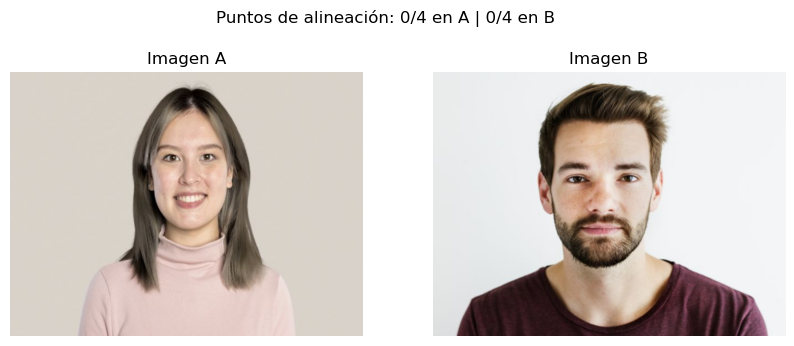

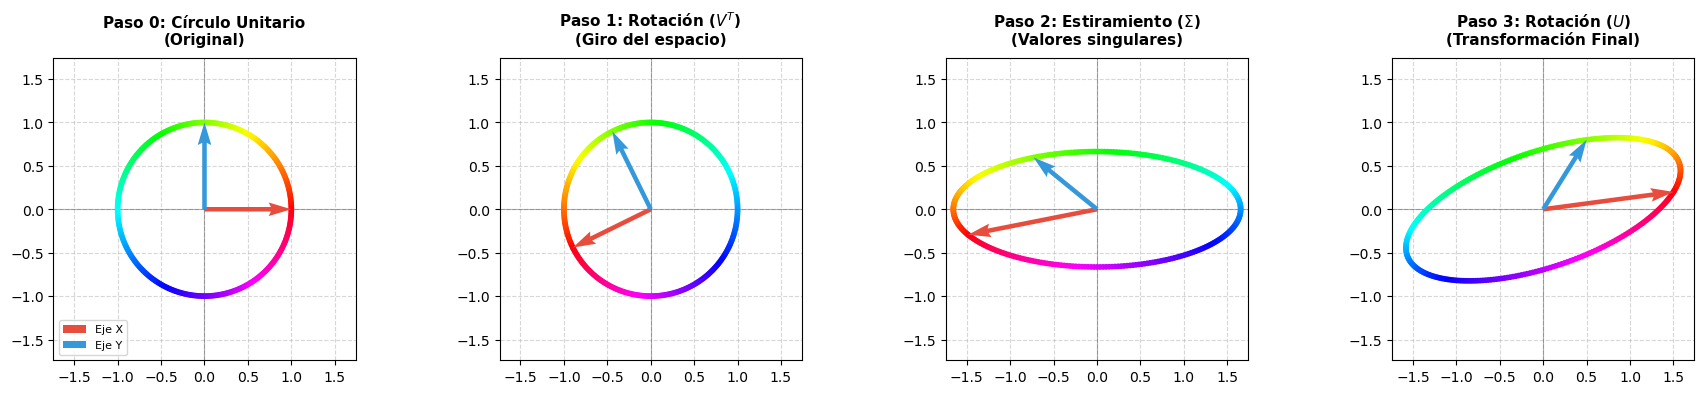

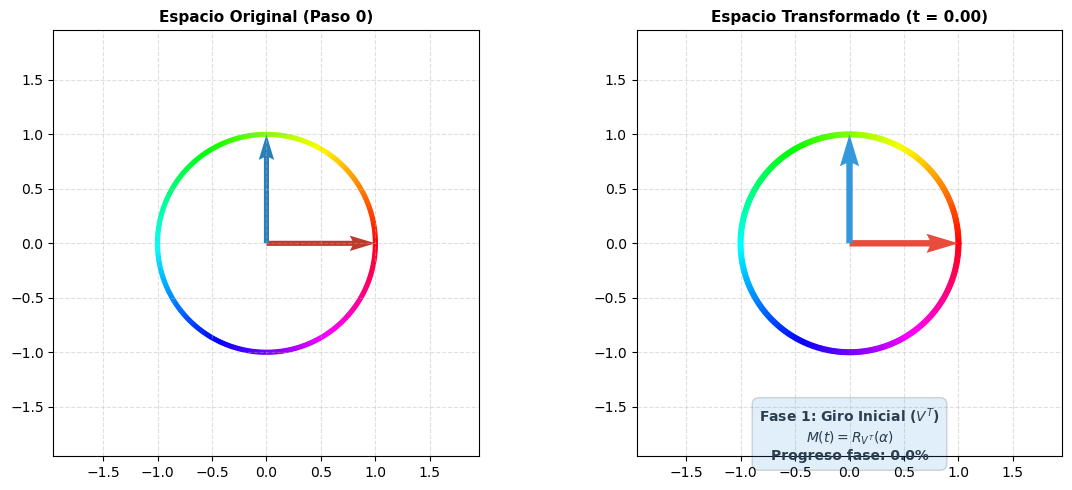

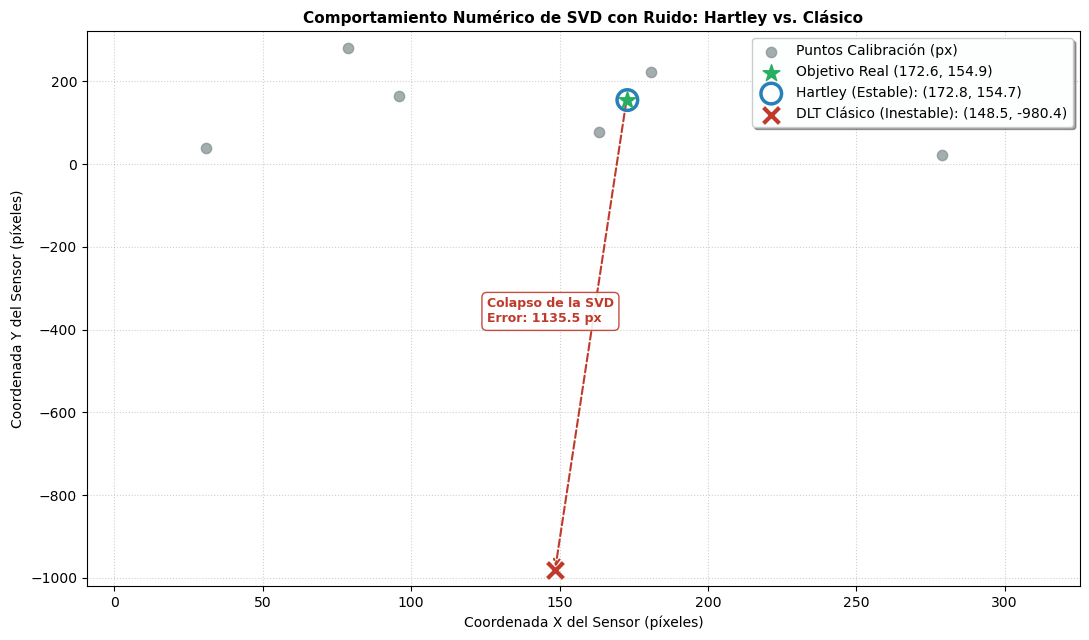

In [6]:
# Forzamos el renderizado estático tradicional (robusto e inmediato)
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

# ==========================================================================
# 1. ESCENARIO GEOGRÁFICO DE PRUEBA (DESAFÍO UTM EXTREMO: 1.000 KM)
# ==========================================================================
# Desplazamos el origen del mosaico 1.000 millones de milímetros (10^9 mm)
offset_utm = np.array([1000000000.0, 1000000000.0], dtype=np.float64)

pts_mundo = np.array([
    [0.0, 0.0],      # Esquina Superior-Izquierda (TL)
    [200.0, 0.0],    # Esquina Superior-Derecha (TR)
    [200.0, 200.0],  # Esquina Inferior-Derecha (BR)
    [0.0, 200.0],    # Esquina Inferior-Izquierda (BL)
    [100.0, 36.0],   # Punta Superior de la estrella interior
    [164.0, 100.0],  # Punta Derecha de la estrella
    [100.0, 164.0],  # Punta Inferior de la estrella
    [36.0, 100.0]    # Punta Izquierda de la estrella
], dtype=np.float64) + offset_utm

# Homografía física teórica de la toma perspectiva
H_verdadera_local = np.array([
    [1.35,  0.30,  30.0],
    [-0.10, 1.45,  40.0],
    [0.0004, 0.0009, 1.0]
], dtype=np.float64)

def proyectar_punto_homogeneo(pt, H):
    pt_hom = np.array([pt[0], pt[1], 1.0], dtype=np.float64)
    res = H @ pt_hom
    return res[:2] / res[2]

# Proyectamos a coordenadas de píxeles locales en el sensor de la cámara
pts_sensor_perfectos = np.array([proyectar_punto_homogeneo(p - offset_utm, H_verdadera_local) for p in pts_mundo])

# Añadimos ruido realista de calibración (error de clic del alumno de 1.5 px)
np.random.seed(42)
ruido = np.random.normal(0, 1.5, pts_sensor_perfectos.shape)
pts_sensor_ruidosos = pts_sensor_perfectos + ruido

# ==========================================================================
# 2. RESOLVER DLT SIN NORMALIZAR (CLÁSICO)
# ==========================================================================
def dlt_sin_normalizar(pts_src, pts_dst):
    A = []
    for i in range(len(pts_src)):
        x, y = pts_src[i][0], pts_src[i][1]
        X, Y = pts_dst[i][0], pts_dst[i][1]
        A.append([0, 0, 0, -x, -y, -1, Y*x, Y*y, Y])
        A.append([x, y, 1, 0, 0, 0, -X*x, -X*y, -X])
    A = np.array(A, dtype=np.float64)
    U, S, Vt = np.linalg.svd(A)
    num_condicion = S[0] / S[-1]
    h = Vt[-1]
    H_estimada = h.reshape((3, 3))
    return H_estimada / H_estimada[2, 2], num_condicion

# ==========================================================================
# 3. RESOLVER DLT CON HARTLEY (NORMALIZADO)
# ==========================================================================
def calcular_matriz_normalizacion(pts):
    centroide = np.mean(pts, axis=0)
    distancia_media = np.mean(np.sqrt(np.sum((pts - centroide)**2, axis=1)))
    factor_escala = np.sqrt(2.0) / distancia_media
    T = np.array([
        [factor_escala, 0, -factor_escala * centroide[0]],
        [0, factor_escala, -factor_escala * centroide[1]],
        [0.0,           0.0,           1.0]
    ], dtype=np.float64)
    return T

def dlt_con_hartley(pts_src, pts_dst):
    T = calcular_matriz_normalizacion(pts_src)
    T_prime = calcular_matriz_normalizacion(pts_dst)
    
    pts_src_norm, pts_dst_norm = [], []
    for i in range(len(pts_src)):
        p_src_h = T @ np.array([pts_src[i][0], pts_src[i][1], 1.0], dtype=np.float64)
        pts_src_norm.append(p_src_h[:2] / p_src_h[2])
        
        p_dst_h = T_prime @ np.array([pts_dst[i][0], pts_dst[i][1], 1.0], dtype=np.float64)
        pts_dst_norm.append(p_dst_h[:2] / p_dst_h[2])
        
    A_norm = []
    for i in range(len(pts_src)):
        x, y = pts_src_norm[i][0], pts_src_norm[i][1]
        X, Y = pts_dst_norm[i][0], pts_dst_norm[i][1]
        A_norm.append([0, 0, 0, -x, -y, -1, Y*x, Y*y, Y])
        A_norm.append([x, y, 1, 0, 0, 0, -X*x, -X*y, -X])
    A_norm = np.array(A_norm, dtype=np.float64)
    
    U, S, Vt = np.linalg.svd(A_norm)
    num_condicion = S[0] / S[-1]
    h_norm = Vt[-1]
    H_norm_estimada = h_norm.reshape((3, 3))
    H_final = np.linalg.inv(T_prime) @ H_norm_estimada @ T
    return H_final / H_final[2, 2], num_condicion

# Estimar ambas homografías (Mundo UTM -> Imagen Cámara)
H_sin, cond_sin = dlt_sin_normalizar(pts_mundo, pts_sensor_ruidosos)
H_con, cond_con = dlt_con_hartley(pts_mundo, pts_sensor_ruidosos)

# Punto de test independiente: centro del azulejo de la Alhambra
pt_test_mundo = np.array([100.0, 100.0], dtype=np.float64) + offset_utm
pt_test_sensor_perfecto = proyectar_punto_homogeneo(pt_test_mundo - offset_utm, H_verdadera_local)

# Proyectar punto de test usando las homografías calculadas
proyeccion_sin = proyectar_punto_homogeneo(pt_test_mundo, H_sin)
proyeccion_con = proyectar_punto_homogeneo(pt_test_mundo, H_con)

# ==========================================================================
# 4. RENDERIZADO VISUAL DEL INFORME GRÁFICO
# ==========================================================================
fig, ax = plt.subplots(figsize=(11, 6.5))

# Puntos de calibración ruidosos
ax.scatter(pts_sensor_ruidosos[:, 0], pts_sensor_ruidosos[:, 1], 
           color='#7F8C8D', marker='o', s=55, label='Puntos Calibración (px)', alpha=0.7)

# Objetivo teórico en el sensor
ax.scatter(pt_test_sensor_perfecto[0], pt_test_sensor_perfecto[1], 
           color='#27AE60', marker='*', s=160, label=f'Objetivo Real ({pt_test_sensor_perfecto[0]:.1f}, {pt_test_sensor_perfecto[1]:.1f})', zorder=5)

# Estimación con Hartley (Debe encajar casi perfecto con el objetivo)
ax.scatter(proyeccion_con[0], proyeccion_con[1], 
           facecolors='none', edgecolors='#2980B9', marker='o', s=220, linewidths=2.5, 
           label=f'Hartley (Estable): ({proyeccion_con[0]:.1f}, {proyeccion_con[1]:.1f})', zorder=4)

# Estimación clásica (Debería salir completamente desplazada y perdida en el gráfico)
ax.scatter(proyeccion_sin[0], proyeccion_sin[1], 
           color='#C0392B', marker='x', s=130, linewidths=3, 
           label=f'DLT Clásico (Inestable): ({proyeccion_sin[0]:.1f}, {proyeccion_sin[1]:.1f})', zorder=4)

# Flecha indicadora de la desviación (Colapso)
ax.annotate('', xy=proyeccion_sin, xytext=pt_test_sensor_perfecto,
            arrowprops=dict(arrowstyle="->", color='#C0392B', linestyle='--', linewidth=1.5))

# Caja con el texto explicativo del error catastrófico
error_dist = np.linalg.norm(proyeccion_sin - pt_test_sensor_perfecto)
ax.text((pt_test_sensor_perfecto[0] + proyeccion_sin[0])/2 - 35, (pt_test_sensor_perfecto[1] + proyeccion_sin[1])/2 + 30, 
        f"Colapso de la SVD\nError: {error_dist:.1f} px", 
        color='#C0392B', fontsize=9, fontweight='bold', bbox=dict(facecolor='white', alpha=0.9, edgecolor='#C0392B', boxstyle='round,pad=0.4'))

# Ajuste automático del encuadre para capturar la magnitud del error
all_x = [pts_sensor_ruidosos[:, 0].min(), pts_sensor_ruidosos[:, 0].max(), pt_test_sensor_perfecto[0], proyeccion_con[0], proyeccion_sin[0]]
all_y = [pts_sensor_ruidosos[:, 1].min(), pts_sensor_ruidosos[:, 1].max(), pt_test_sensor_perfecto[1], proyeccion_con[1], proyeccion_sin[1]]
ax.set_xlim(min(all_x) - 40, max(all_x) + 40)
ax.set_ylim(min(all_y) - 40, max(all_y) + 40)

ax.set_title("Comportamiento Numérico de SVD con Ruido: Hartley vs. Clásico", fontsize=11, fontweight='bold')
ax.set_xlabel("Coordenada X del Sensor (píxeles)", fontsize=10)
ax.set_ylabel("Coordenada Y del Sensor (píxeles)", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', frameon=True, shadow=True, facecolor='#FDFEFE')

plt.tight_layout()
plt.show()

# Cuarta parte.- Medir sobre imágenes

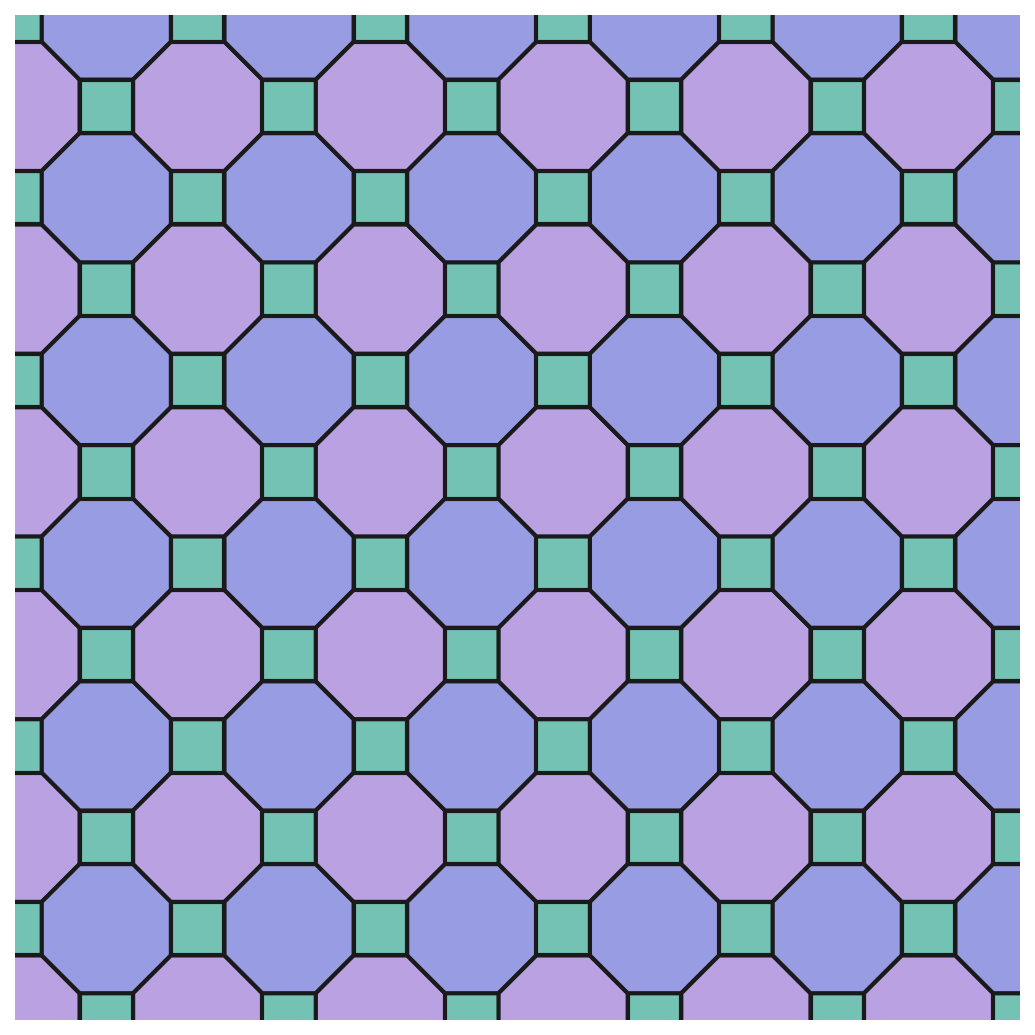

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def generar_teselado_488(grid_size=5, tile_side=1.0, dpi=150):
    s = tile_side
    # Distancia matemática exacta entre centros de azulejos
    hs = s * (1 + np.sqrt(2)/2)
    
    fig, ax = plt.subplots(figsize=(7, 7), dpi=dpi)
    ax.set_aspect('equal')
    
    # Colores pastel del mosaico original
    color_purple = '#BAA2E2'  # Lavanda Nazarí
    color_blue   = '#989DE3'  # Azul Nazarí
    color_teal   = '#74C2B4'  # Turquesa/Teal
    color_line   = '#1A1A1A'  # Línea de junta (carboncillo)
    
    # Dibujamos en un rango extendido para asegurar que el corte de cámara sea limpio
    for i in range(-1, grid_size + 2):
        for j in range(-1, grid_size + 2):
            cx, cy = i * hs, j * hs
            
            # 1. CASO OCTÁGONO (i + j es par)
            if (i + j) % 2 == 0:
                hW = s * (1 + np.sqrt(2)) / 2
                hs_half = s / 2
                
                # Coordenadas de los 8 vértices del octágono regular
                oct_verts = np.array([
                    [cx - hs_half, cy + hW], [cx + hs_half, cy + hW],
                    [cx + hW, cy + hs_half], [cx + hW, cy - hs_half],
                    [cx + hs_half, cy - hW], [cx - hs_half, cy - hW],
                    [cx - hW, cy - hs_half], [cx - hW, cy + hs_half]
                ])
                
                # Alternancia de color en diagonal (checkerboard de octágonos)
                fill_color = color_purple if i % 2 == 0 else color_blue
                
                polygon = patches.Polygon(oct_verts, closed=True, 
                                          facecolor=fill_color, edgecolor=color_line, 
                                          linewidth=2.0, zorder=2)
                ax.add_patch(polygon)
                
            # 2. CASO CUADRADO (i + j es impar)
            else:
                sq_verts = np.array([
                    [cx - s/2, cy + s/2], [cx + s/2, cy + s/2],
                    [cx + s/2, cy - s/2], [cx - s/2, cy - s/2]
                ])
                
                polygon = patches.Polygon(sq_verts, closed=True, 
                                          facecolor=color_teal, edgecolor=color_line, 
                                          linewidth=2.0, zorder=2)
                ax.add_patch(polygon)
                
    # Encuadre y recorte perfecto de la visualización
    ax.set_xlim(0, (grid_size - 1) * hs)
    ax.set_ylim(0, (grid_size - 1) * hs)
    
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# Ejecutar el generador procedimental en tu celda
generar_teselado_488(grid_size=12)

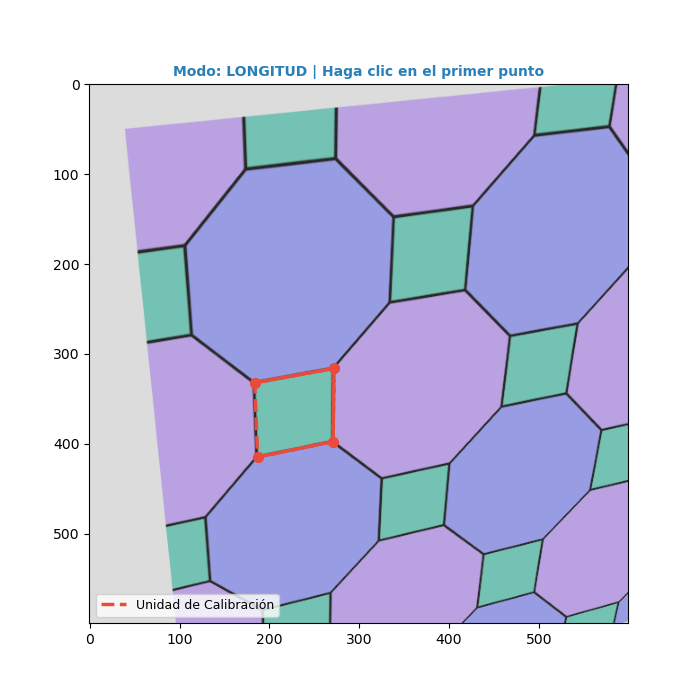

In [7]:
# Activa el modo interactivo (Opcional, requiere !pip install ipympl)
%matplotlib widget

# ==========================================================================
# 1. GENERACIÓN PROCEDURAL DE LA TESELACIÓN TRUNCADA 4.8.8
# ==========================================================================
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import HBox, VBox, Layout

def generar_imagen_teselado(grid_size=5, s=100.0):
    """Genera la imagen del mosaico 4.8.8 con precisión matemática"""
    hs = s * (1 + np.sqrt(2)/2)
    width = int(grid_size * hs)
    height = int(grid_size * hs)
    img = np.ones((height, width, 3), dtype=np.uint8) * 245
    
    # Paleta de colores pastel del mosaico original (BGR para OpenCV)
    color_purple = (226, 162, 186)  # Lavanda Nazarí
    color_blue   = (227, 157, 152)  # Azul Nazarí
    color_teal   = (180, 194, 116)  # Turquesa/Teal
    color_line   = (40, 40, 40)      # Junta de unión
    
    for i in range(-1, grid_size + 2):
        for j in range(-1, grid_size + 2):
            cx, cy = i * hs, j * hs
            
            # Octágonos (i + j es par)
            if (i + j) % 2 == 0:
                hW = s * (1 + np.sqrt(2)) / 2
                hs_half = s / 2
                oct_verts = np.array([
                    [cx - hs_half, cy + hW], [cx + hs_half, cy + hW],
                    [cx + hW, cy + hs_half], [cx + hW, cy - hs_half],
                    [cx + hs_half, cy - hW], [cx - hs_half, cy - hW],
                    [cx - hW, cy - hs_half], [cx - hW, cy + hs_half]
                ], dtype=np.int32)
                
                fill_color = color_purple if i % 2 == 0 else color_blue
                cv2.fillPoly(img, [oct_verts], fill_color)
                cv2.polylines(img, [oct_verts], True, color_line, 2, cv2.LINE_AA)
                
            # Cuadrados (i + j es impar)
            else:
                sq_verts = np.array([
                    [cx - s/2, cy + s/2], [cx + s/2, cy + s/2],
                    [cx + s/2, cy - s/2], [cx - s/2, cy - s/2]
                ], dtype=np.int32)
                
                cv2.fillPoly(img, [sq_verts], color_teal)
                cv2.polylines(img, [sq_verts], True, color_line, 2, cv2.LINE_AA)
                
    return img

# ==========================================================================
# 2. ESCENARIO DE SIMULACIÓN Y CALIBRACIÓN
# ==========================================================================
s_lado = 100.0  # Lado de los cuadrados/octágonos en mm reales
img_base = generar_imagen_teselado(grid_size=5, s=s_lado)

# Aplicamos una homografía de deformación de cámara (Mundo -> Sensor)
H_verdadera = np.array([
    [1.15,  0.15,  40.0],
    [-0.10, 1.25,  50.0],
    [0.0003, 0.0006, 1.0]
], dtype=np.float64)

img_distorsionada = cv2.warpPerspective(img_base, H_verdadera, (600, 600), borderValue=(220, 220, 220))

# Buscamos el primer cuadrado totalmente visible (i=1, j=2) en el mundo
hs_val = s_lado * (1 + np.sqrt(2)/2)
cx, cy = 1 * hs_val, 2 * hs_val
sq_world = np.array([
    [cx - s_lado/2, cy - s_lado/2], # Superior-Izquierda (TL)
    [cx + s_lado/2, cy - s_lado/2], # Superior-Derecha (TR)
    [cx + s_lado/2, cy + s_lado/2], # Inferior-Derecha (BR)
    [cx - s_lado/2, cy + s_lado/2]  # Inferior-Izquierda (BL)
], dtype=np.float64)

# Proyectamos las esquinas teóricas de este cuadrado al plano del sensor
def proyectar_puntos(pts, H):
    pts_hom = np.hstack([pts, np.ones((len(pts), 1))])
    res = (H @ pts_hom.T).T
    return res[:, :2] / res[:, 2:]

sq_sensor = proyectar_puntos(sq_world, H_verdadera)

# --------------------------------------------------------------------------
# CÁLCULO DE LA HOMOGRAFÍA DE RECTIFICACIÓN AL CUADRADO UNIDAD
# --------------------------------------------------------------------------
sq_unidad = np.array([
    [0.0, 1.0],  # TL -> Arriba izquierda de la unidad
    [1.0, 1.0],  # TR -> Arriba derecha
    [1.0, 0.0],  # BR -> Abajo derecha
    [0.0, 0.0]   # BL -> Abajo izquierda
], dtype=np.float32)

H_rect = cv2.getPerspectiveTransform(sq_sensor.astype(np.float32), sq_unidad)

# --------------------------------------------------------------------------
# NÚCLEO MATEMÁTICO DEL PUENTE MÉTRICO
# --------------------------------------------------------------------------
def sensor_a_unidad(pt, H):
    pt_hom = np.array([pt[0], pt[1], 1.0], dtype=np.float64)
    res = H @ pt_hom
    return res[:2] / res[2]

def calcular_distancia_real(pt1, pt2, H_rect, s):
    u1 = sensor_a_unidad(pt1, H_rect)
    u2 = sensor_a_unidad(pt2, H_rect)
    return np.linalg.norm(u1 - u2) * s

def calcular_angulo_real(pt1, pt2, pt3, H_rect):
    u1 = sensor_a_unidad(pt1, H_rect)
    u2 = sensor_a_unidad(pt2, H_rect)
    u3 = sensor_a_unidad(pt3, H_rect)
    v1 = u1 - u2
    v2 = u3 - u2
    cos_t = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-8)
    return np.degrees(np.arccos(np.clip(cos_t, -1.0, 1.0)))

# ==========================================================================
# 3. CLASE CONTROLADORA INTERACTIVA DE METROLOGÍA
# ==========================================================================
class MedidorPlanoAlhambra:
    def __init__(self, img, H_rect, s):
        self.img = img
        self.H_rect = H_rect
        self.s = s
        self.pts_clicados = []
        self.graficos_permanentes = []
        self.graficos_parciales = []
        self.modo = 'Longitud' # 'Longitud' o 'Ángulo'
        
        self.fig, self.ax = plt.subplots(figsize=(7, 7))
        self.ax.imshow(cv2.cvtColor(self.img, cv2.COLOR_BGR2RGB))
        
        # Dibujamos y resaltamos el cuadrado de calibración
        poly_calib = np.vstack([sq_sensor, sq_sensor])
        self.ax.plot(poly_calib[:, 0], poly_calib[:, 1], color='#E74C3C', linewidth=2.5, linestyle='--', label='Unidad de Calibración')
        self.ax.scatter(sq_sensor[:, 0], sq_sensor[:, 1], color='#E74C3C', s=50, zorder=5)
        
        self.ax.legend(loc='lower left', fontsize=9)
        self.ax.axis('on')
        self.actualizar_titulo_instrucciones()
        
        # Conectar el manejador de eventos por clics
        self.cid = self.fig.canvas.mpl_connect('button_press_event', self.onclick)

    def actualizar_titulo_instrucciones(self):
        """Actualiza de forma dinámica las instrucciones en el título según el estado de los clics"""
        if self.modo == 'Longitud':
            n = len(self.pts_clicados)
            if n == 0:
                self.ax.set_title("Modo: LONGITUD | Haga clic en el primer punto", color='#2980B9', fontsize=10, fontweight='bold')
            else:
                self.ax.set_title("Modo: LONGITUD | Clic en el segundo punto para medir la distancia", color='#D35400', fontsize=10, fontweight='bold')
        elif self.modo == 'Ángulo':
            n = len(self.pts_clicados)
            if n == 0:
                self.ax.set_title("Modo: ÁNGULO | Haga clic en el primer extremo", color='#27AE60', fontsize=10, fontweight='bold')
            elif n == 1:
                self.ax.set_title("Modo: ÁNGULO | Clic en el segundo punto (¡Será el VÉRTICE del ángulo!)", color='#D35400', fontsize=10, fontweight='bold')
            else:
                self.ax.set_title("Modo: ÁNGULO | Clic en el tercer punto (Segundo extremo)", color='#D35400', fontsize=10, fontweight='bold')
        self.fig.canvas.draw_idle()

    def onclick(self, event):
        if event.xdata is None or event.ydata is None or event.inaxes != self.ax:
            return
        
        pt = np.array([event.xdata, event.ydata])
        self.pts_clicados.append(pt)
        
        # Pintar el punto actual de forma provisional
        color_pt = '#2980B9' if self.modo == 'Longitud' else '#27AE60'
        p_plot = self.ax.scatter(pt[0], pt[1], color=color_pt, s=70, edgecolors='white', linewidths=1.5, zorder=6)
        self.graficos_parciales.append(p_plot)
        
        n_pts = len(self.pts_clicados)
        
        # CASO 2 CLICS: Distancia
        if self.modo == 'Longitud' and n_pts == 2:
            p1, p2 = self.pts_clicados[0], self.pts_clicados[1]
            dist = calcular_distancia_real(p1, p2, self.H_rect, self.s)
            
            line, = self.ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color='#2980B9', linewidth=3.5, zorder=4)
            self.graficos_permanentes.append(line)
            # Consolidamos puntos provisionales como permanentes
            self.graficos_permanentes.extend(self.graficos_parciales)
            self.graficos_parciales = []
            
            self.ax.set_title(f"📏 Distancia Calculada: {dist:.1f} mm (Mundo real)", color='#2980B9', fontsize=11, fontweight='bold')
            self.pts_clicados = []
            
        # CASO 3 CLICS: Ángulo
        elif self.modo == 'Ángulo' and n_pts == 3:
            p1, p2, p3 = self.pts_clicados[0], self.pts_clicados[1], self.pts_clicados[2]
            ang = calcular_angulo_real(p1, p2, p3, self.H_rect)
            
            line1, = self.ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color='#27AE60', linewidth=3.5, zorder=4)
            line2, = self.ax.plot([p2[0], p3[0]], [p2[1], p3[1]], color='#27AE60', linewidth=3.5, zorder=4)
            self.graficos_permanentes.extend([line1, line2])
            # Consolidamos puntos provisionales como permanentes
            self.graficos_permanentes.extend(self.graficos_parciales)
            self.graficos_parciales = []
            
            self.ax.set_title(f"📐 Ángulo en el Vértice: {ang:.1f}° (Mundo real)", color='#27AE60', fontsize=11, fontweight='bold')
            self.pts_clicados = []
        else:
            self.actualizar_titulo_instrucciones()
            
        self.fig.canvas.draw_idle()

    def cambiar_modo(self, nuevo_modo):
        self.modo = nuevo_modo
        self.limpiar_parciales()
        self.actualizar_titulo_instrucciones()

    def limpiar_parciales(self):
        """Elimina del gráfico las marcas de clics inconclusos al cambiar de modo"""
        for g in self.graficos_parciales:
            try:
                g.remove()
            except Exception:
                pass
        self.graficos_parciales = []
        self.pts_clicados = []
        self.fig.canvas.draw_idle()

    def limpiar_todo(self):
        """Borra por completo todas las mediciones realizadas de la pantalla"""
        for g in self.graficos_permanentes + self.graficos_parciales:
            try:
                g.remove()
            except Exception:
                pass
        self.graficos_permanentes = []
        self.graficos_parciales = []
        self.pts_clicados = []
        self.actualizar_titulo_instrucciones()

# ==========================================================================
# 4. CONSTRUCCIÓN DE LA INTERFAZ DE USUARIO (WIDGETS)
# ==========================================================================
# Inicializar la aplicación
medidor = MedidorPlanoAlhambra(img_distorsionada, H_rect, s_lado)

# Selector de modo (Botón conmutable)
selector_modo = widgets.ToggleButtons(
    options=['Longitud', 'Ángulo'],
    value='Longitud',
    description='Herramienta:',
    button_style='', # '', 'success', 'info', 'warning', 'danger'
    tooltips=['Mide distancias en milímetros reales', 'Mide ángulos en grados de diseño'],
    style={'button_width': '120px'}
)

# Botón de reset
boton_limpiar = widgets.Button(
    description='Limpiar Mediciones',
    disabled=False,
    button_style='danger', # Rojo de aviso
    tooltip='Borra todas las líneas y ángulos dibujados',
    icon='trash',
    layout=Layout(width='180px')
)

# Callbacks de los botones
def on_modo_change(change):
    medidor.cambiar_modo(change['new'])

def on_click_limpiar(b):
    medidor.limpiar_todo()

selector_modo.observe(on_modo_change, names='value')
boton_limpiar.on_click(on_click_limpiar)

# Mostrar contenedor horizontal estético
display(HBox([selector_modo, boton_limpiar], layout=Layout(margin='10px 0px', gap='20px')))


## Instrucciones de uso para los alumnos:


El panel de control interactivo: Un par de botones grandes para conmutar entre la herramienta "Longitud" (azul) y "Ángulo" (verde), situados junto a un botón rojo con un icono de papelera ("Limpiar Mediciones").

La guía visual de calibración: El cuadrado rojo discontinuo indica sobre qué pieza se ha calibrado la homografía (el cuadrado unidad). Esto les ayuda a ver espacialmente la referencia del sistema.

Funcionamiento ergonómico:

Para medir una distancia: Conmutan a Longitud. Hacen clic en el punto A, luego en el B. Se trazará una línea azul recta y el título de la figura les dirá, por ejemplo: "Distancia Calculada: 141.4 mm" (la diagonal exacta de un azulejo de 100 mm).

Para medir un ángulo: Conmutan a Ángulo. Hacen tres clics seguidos en orden (Extremo 1 → Vértice → Extremo 2). La aplicación dibujará dos segmentos verdes conectados en el vértice e informará inmediatamente del ángulo de diseño real (por ejemplo, "Ángulo en el Vértice: 135.0°" si miden una punta del octágono, o "90.0°" si miden el cuadrado).